# Data Matching in Python: Duplicate Detection and Record Linkage with Splink
## 1. Introduction
Two records can describe the same transaction without being identical. Probabilistic
record linkage combines agreement on several fields rather than relying on a single key.
Here we use the **same Splink transaction datasets** in two experiments:
duplicate detection within destination transactions (`dedupe_only`), and linkage from
origin to the original destination dataset (`link_only`).

This revision preserves the original load–explore–inject–match–evaluate workflow and its
useful exact-duplicate and date/amount EDA. It adds realistic perturbations, a separate
training partition, blocking diagnostics, threshold evaluation and the second experiment.
The synthetic benchmark tests recovery of controlled errors; it is not evidence of
production reconciliation accuracy. All results below are computed when the notebook runs.

### Environment and Splink 5 API
Use Python 3.12 and install the adjacent `requirements.txt` in a clean environment;
select that environment as the Jupyter kernel. The first download needs internet access.
Splink 5 registers data with `DuckDBAPI.register()` **before** constructing `Linker`.
`SettingsCreator` describes comparisons, identifiers and blocking; `DuckDBAPI` supplies
the SQL backend; `Linker` combines registered tables with those settings.
The installed API signatures are displayed rather than inferred from Splink 4 examples.

In [1]:
import inspect
import itertools
import time
import copy
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display, Markdown
from splink import DuckDBAPI, Linker, SettingsCreator, splink_datasets
import splink.comparison_library as cl

assert version('splink') == '5.0.0', 'Install splink==5.0.0 before running.'
SEED = 42
THRESHOLDS = [0.5, 0.7, 0.8, 0.9, 0.95]
REPORT_THRESHOLD = 0.8  # fixed before examining test results
U_MAX_PAIRS = 10_000_000  # increase for a final sensitivity study of rare levels
for package in ['splink', 'duckdb', 'pandas', 'numpy', 'matplotlib']:
    print(package, version(package))
for obj in [SettingsCreator, DuckDBAPI.register, Linker,
            cl.JaroWinklerAtThresholds, cl.ExactMatch]:
    print(obj.__name__, inspect.signature(obj))

splink 5.0.0
duckdb 2.0.0
pandas 3.1.0
numpy 2.5.4
matplotlib 3.11.2
SettingsCreator (link_type: "Literal['link_only', 'link_and_dedupe', 'dedupe_only']", comparisons: 'List[ComparisonCreator | dict[str, Any]]' = <factory>, blocking_rules_to_generate_predictions: 'List[BlockingRuleCreator | dict[str, Any]]' = <factory>, probability_two_random_records_match: 'float' = 0.0001, em_convergence: 'float' = 0.0001, max_iterations: 'int' = 25, retain_matching_columns: 'bool' = True, retain_intermediate_calculation_columns: 'bool' = False, additional_columns_to_retain: 'List[str]' = <factory>, unique_id_column_name: 'str' = 'unique_id', source_dataset_column_name: 'str' = 'source_dataset', match_weight_column_prefix: 'str' = 'mw_', term_frequency_adjustment_column_prefix: 'str' = 'tf_', comparison_vector_value_column_prefix: 'str' = 'gamma_', linker_uid: 'str | None' = None) -> None
register (self, table: 'AcceptableInputTableType | str', *, dataset_display_name: 'Optional[str]' = None, table_n

## 2. Dataset Exploration
`unique_id` identifies a row, while `ground_truth` identifies its underlying transaction.
`memo` is descriptive text, `transaction_date` is a posting date and `amount` is a
financial amount. Equal dates and amounts can occur for unrelated transactions.
We inspect both tables and check label completeness and multiplicity instead of
assuming one row per transaction. Matching row IDs across sources are never used as evidence.

In [2]:
data_dir = Path('data')  # distributed alongside this notebook
if all((data_dir / (name + '.parquet')).exists()
       for name in ['transactions_origin', 'transactions_destination']):
    df_origin = pd.read_parquet(data_dir / 'transactions_origin.parquet')
    df_destination = pd.read_parquet(data_dir / 'transactions_destination.parquet')
    print('Using bundled snapshots of the Splink transaction samples.')
else:
    df_origin = splink_datasets.transactions_origin.to_pandas()
    df_destination = splink_datasets.transactions_destination.to_pandas()
origin_snapshot = df_origin.copy(deep=True)
destination_snapshot = df_destination.copy(deep=True)
required = {'unique_id', 'ground_truth', 'memo', 'transaction_date', 'amount'}
for name, frame in [('origin', df_origin), ('destination', df_destination)]:
    assert required <= set(frame.columns)
    assert frame.unique_id.is_unique and frame.unique_id.notna().all()
    assert frame.ground_truth.notna().all(), 'Incomplete truth needs an explicit evaluation policy.'
    print(name, 'rows:', len(frame), 'entities:', frame.ground_truth.nunique())
    display(frame.dtypes.to_frame('dtype'))
    display(pd.DataFrame({'missing': frame.isna().sum(), 'unique': frame.nunique()}))
    display(frame.head())
    display(frame.groupby('ground_truth').size().value_counts().sort_index()
            .rename_axis('records per entity').to_frame('entities'))
shared_labels = set(df_origin.ground_truth) & set(df_destination.ground_truth)
print('Shared transaction identities:', len(shared_labels))
assert shared_labels, 'Cross-source labels must be verified before evaluation.'

Using bundled snapshots of the Splink transaction samples.
origin rows: 45326 entities: 45326


,dtype
ground_truth,int64
memo,str
transaction_date,object
amount,float64
unique_id,int64


,missing,unique
ground_truth,0,45326
memo,0,34358
transaction_date,0,130
amount,0,35983
unique_id,0,45326


,ground_truth,memo,transaction_date,amount,unique_id
0,0,MATTHIAS C paym,2022-03-28,36.36,0
1,1,M CORVINUS dona,2022-02-14,221.91,1
2,2,M C donation BG,2022-05-04,449.79,2
3,3,M C BGC,2022-03-03,208.45,3
4,4,M CORVINUS CSH,2022-02-04,79.74,4


,entities
records per entity,
1,45326


...

,dtype
ground_truth,int64
memo,str
transaction_date,object
amount,float64
unique_id,int64


,missing,unique
ground_truth,0,45326
memo,0,36010
transaction_date,0,149
amount,0,34187
unique_id,0,45326


,ground_truth,memo,transaction_date,amount,unique_id
0,0,MATTHIAS C payment BGC,2022-03-29,36.36,0
1,1,M CORVINUS BGC,2022-02-16,221.91,1
2,2,M C,2022-05-05,449.79,2
3,3,M C payment,2022-03-04,198.79,3
4,4,M CORVINUS,2022-02-05,79.74,4


,entities
records per entity,
1,45326


Shared transaction identities: 45326


## 3. Data Preparation and Controlled Duplicate Generation
The originals stay unchanged. We copy 10% of destination rows, retain their transaction
identity and assign new, globally unique string row IDs. Easy copies lose one interior
character; medium copies also shift the date by one day; hard copies receive two text
edits, a two/three-day shift and a 1–50 cent amount change. These are illustrative posting
and transcription errors, not a universal financial-error model. Amount changes retain
the original sign. Difficulty labels and parent IDs are audit metadata, never features.

The identity split is fixed before model fitting: 35% training/calibration, 65% test.
All copies and both sources for an entity remain together. This prevents direct entity
leakage. EDA is descriptive; rules and the reporting threshold are fixed in code.

In [3]:
def prepare(frame, source):
    out = frame.copy(deep=True)
    out['record_id'] = source + ':' + out.unique_id.astype(str)
    out['memo'] = (out.memo.astype('string').str.upper()
                   .str.replace(r'\s+', ' ', regex=True).str.strip())
    out['transaction_date'] = pd.to_datetime(out.transaction_date, errors='raise')
    assert out.transaction_date.notna().all() and out.amount.notna().all()
    out['amount_cents'] = np.rint(pd.to_numeric(out.amount) * 100).astype('int64')
    out['day'] = (out.transaction_date - pd.Timestamp('1970-01-01')).dt.days.astype('int64')
    out['memo_prefix'] = out.memo.str[:3]
    return out

def inject_duplicates(base, seed=SEED):
    rng = np.random.default_rng(seed)
    original = base.copy(deep=True)
    original['difficulty'] = 'original'
    original['parent_record_id'] = original.record_id
    copies = original.iloc[rng.choice(len(original), round(len(original)*0.10), replace=False)].copy()
    levels = np.resize(np.array(['easy', 'medium', 'hard']), len(copies))
    rng.shuffle(levels)
    copies['difficulty'] = levels
    copies['record_id'] = ['synthetic:' + str(i) for i in range(len(copies))]
    def edit(value, edits):
        if pd.isna(value):
            return value
        text = str(value)
        for _ in range(edits):
            if len(text) > 3:
                pos = int(rng.integers(1, len(text)-1))
                text = text[:pos] + text[pos+1:]
            elif text:
                text += '.'
        return text
    copies['memo'] = [edit(m, 2 if d == 'hard' else 1)
                      for m, d in zip(copies.memo, copies.difficulty)]
    offsets = [0 if d == 'easy' else int(rng.choice([-1,1]) if d == 'medium'
              else rng.choice([-3,-2,2,3])) for d in copies.difficulty]
    copies['day'] += offsets
    hard = copies.difficulty.eq('hard')
    delta = rng.integers(1, 51, int(hard.sum()))
    copies.loc[hard, 'amount_cents'] += np.where(copies.loc[hard, 'amount_cents'] < 0, -delta, delta)
    copies['amount'] = copies.amount_cents / 100
    copies['transaction_date'] = pd.Timestamp('1970-01-01') + pd.to_timedelta(copies.day, unit='D')
    copies['memo_prefix'] = copies.memo.str[:3]
    result = pd.concat([original, copies], ignore_index=True)
    assert result.record_id.is_unique
    assert copies.ground_truth.equals(original.set_index('record_id')
           .loc[copies.parent_record_id, 'ground_truth'].set_axis(copies.index))
    return result

origin = prepare(df_origin, 'origin')
destination = prepare(df_destination, 'destination')
dedupe_data = inject_duplicates(destination)
pd.testing.assert_frame_equal(dedupe_data, inject_duplicates(destination))
all_entities = sorted(set(origin.ground_truth) | set(destination.ground_truth))
permuted = np.random.default_rng(SEED).permutation(all_entities)
training_entities = set(permuted[:round(0.35 * len(permuted))])
def split_entities(frame):
    mask = frame.ground_truth.isin(training_entities)
    return frame.loc[mask].copy(), frame.loc[~mask].copy()
dedupe_train, dedupe_test = split_entities(dedupe_data)
origin_train, origin_test = split_entities(origin)
destination_train, destination_test = split_entities(destination)
assert not set(dedupe_train.ground_truth) & set(dedupe_test.ground_truth)
print('Original / injected / total:', len(destination), len(dedupe_data)-len(destination), len(dedupe_data))
display(pd.crosstab(dedupe_data.difficulty,
                    np.where(dedupe_data.ground_truth.isin(training_entities), 'train', 'test')))

Original / injected / total: 45326 4533 49859


col_0,test,train
difficulty,,
easy,1018,493
hard,1005,506
medium,972,539
original,29462,15864


### Exact duplicates and potentially ambiguous groups
The original notebook's exact-duplicate search is retained, now on the explicit
experiment table. The count is computed below; it is not hard-coded into the narrative.
Identical feature values are a baseline, not ground truth. Grouping on date and amount
also reveals legitimate collisions that a probabilistic model must distinguish.

In [4]:
match_columns = ['memo', 'transaction_date', 'amount_cents']
exact_duplicates = dedupe_data[dedupe_data.duplicated(subset=match_columns, keep=False)]
print('Rows in exact duplicate feature groups:', len(exact_duplicates))
display(exact_duplicates.sort_values(match_columns).head(20))
candidate_groups = (dedupe_data.groupby(['transaction_date','amount_cents'])
    .agg(records=('record_id','count'), unique_memos=('memo','nunique')).reset_index())
display(candidate_groups.query('records > 1 and unique_memos > 1')
        .sort_values('records', ascending=False).head(20))

Rows in exact duplicate feature groups: 0


,ground_truth,memo,transaction_date,amount,unique_id,record_id,amount_cents,day,memo_prefix,difficulty,parent_record_id


,transaction_date,amount_cents,records,unique_memos
21173,2022-03-30,16854,3,3
20908,2022-03-29,2114411,3,3
10957,2022-03-06,8426,3,3
16779,2022-03-21,6952,3,3
27961,2022-04-12,49625,3,3
30442,2022-04-17,3417,3,3
31117,2022-04-18,5909,3,3
31338,2022-04-18,25288,3,3
34294,2022-04-23,15696,3,3
47813,2022-05-18,12531,2,2


## 4. Duplicate Detection with Splink
Comparisons place each pair in one mutually exclusive level per field. Jaro–Winkler
measures character agreement and transpositions, with a bonus for a common prefix;
it is useful for short description edits but is not semantic understanding. We retain
the original 0.95/0.90/0.80 thresholds. `ExactMatch` has null, exact and disagreement
levels; the original exact-amount/date setup is useful as a baseline but cannot describe
the severity of date and amount differences. Our main model adds explicit tolerance levels.

Blocking is an OR of candidate-generation rules, not proof of a match. We preselect a
targeted union: exact amount within fourteen days, or a shared three-character memo prefix
within fourteen days and either 50 cents or 15% of the larger absolute amount. We also count candidates for stricter and original broad
strategies. No scoring threshold can recover a true pair that blocking excludes.

In [5]:
STRICT = 'l.amount_cents = r.amount_cents AND l.day = r.day'
BROAD = ['l.amount_cents = r.amount_cents', 'l.day = r.day']
TARGETED = [
    'l.amount_cents = r.amount_cents AND abs(l.day-r.day) <= 14',
    'l.memo_prefix = r.memo_prefix AND abs(l.day-r.day) <= 14 AND '
    '(abs(l.amount_cents-r.amount_cents) <= 50 OR '
    'abs(l.amount_cents-r.amount_cents) <= 0.15*greatest(abs(l.amount_cents),abs(r.amount_cents)))'
]
PRIOR_RULE = ('l.amount_cents = r.amount_cents AND abs(l.day-r.day) <= 3 '
              'AND jaro_winkler_similarity(l.memo,r.memo) >= 0.95')
FEATURES = ['record_id', 'memo', 'amount_cents', 'day', 'memo_prefix']

def tolerance_comparison(column, thresholds, relative_thresholds=()):
    return {'output_column_name': column, 'comparison_levels': [
        {'sql_condition': f'{column}_l IS NULL OR {column}_r IS NULL',
         'label_for_charts': 'Missing', 'is_null_level': True},
        {'sql_condition': f'{column}_l = {column}_r', 'label_for_charts': 'Exact'},
        *[{'sql_condition': f'abs({column}_l-{column}_r) <= {t}',
           'label_for_charts': f'Absolute difference <= {t}'} for t in thresholds],
        *[{'sql_condition': f'abs({column}_l-{column}_r) <= {t}*greatest(abs({column}_l),abs({column}_r))',
           'label_for_charts': f'Relative difference <= {t:.0%}'} for t in relative_thresholds],
        {'sql_condition': 'ELSE', 'label_for_charts': 'All other comparisons'}]}

def make_settings(link_type, rules=TARGETED):
    return SettingsCreator(
        link_type=link_type, unique_id_column_name='record_id',
        comparisons=[cl.JaroWinklerAtThresholds('memo', [0.95,0.90,0.80]),
                     tolerance_comparison('amount_cents', [10,50], [.01,.05,.15]),
                     tolerance_comparison('day', [1,3,7,14])],
        blocking_rules_to_generate_predictions=rules,
        retain_intermediate_calculation_columns=True)

# Keep the exact comparison API visible as the original baseline specification.
exact_baseline_comparisons = [cl.ExactMatch('amount_cents'), cl.ExactMatch('day')]

def pair_set(frame, link_type):
    pairs = zip(frame.record_id_l, frame.record_id_r)
    return {tuple(sorted(p)) if link_type == 'dedupe_only' else tuple(p) for p in pairs}

def truth_pairs(left, right=None):
    if right is None:
        return {p for _, g in left.groupby('ground_truth')
                for p in itertools.combinations(sorted(g.record_id), 2)}
    joined = left[['ground_truth','record_id']].merge(
        right[['ground_truth','record_id']], on='ground_truth', suffixes=('_l','_r'))
    return set(zip(joined.record_id_l, joined.record_id_r))

def candidate_stats(left, rules, right=None):
    # Independent SQL audit: no candidate dataframe needs to be materialised in Python.
    with duckdb.connect() as con:
        con.register('left_rows', left)
        con.register('right_rows', left if right is None else right)
        allowed = 'l.record_id < r.record_id' if right is None else 'TRUE'
        condition = ' OR '.join('(' + rule + ')' for rule in rules)
        count, true_count = con.execute(f"""
            SELECT count(*), count(*) FILTER (WHERE l.ground_truth = r.ground_truth)
            FROM left_rows l JOIN right_rows r ON ({condition}) AND ({allowed})
        """).fetchone()
    return int(count), int(true_count)

def blocking_report(left, right=None):
    true = truth_pairs(left, right)
    possible = len(left)*(len(left)-1)//2 if right is None else len(left)*len(right)
    rows = []
    for name, rules in [('strict', [STRICT]), ('original broad', BROAD), ('targeted', TARGETED)]:
        start = time.perf_counter()
        count, recovered = candidate_stats(left, rules, right)
        rows.append(dict(strategy=name, candidates=count, possible_pairs=possible,
                         reduction_ratio=1-count/possible,
                         blocking_recall=recovered/len(true) if true else np.nan,
                         count_seconds=time.perf_counter()-start))
    return pd.DataFrame(rows)

dedupe_truth = truth_pairs(dedupe_test)
dedupe_blocking = blocking_report(dedupe_test)
display(dedupe_blocking)

,strategy,candidates,possible_pairs,reduction_ratio,blocking_recall,count_seconds
0,strict,1094,526712196,0.999998,0.339900,0.077462
1,original broad,5221749,526712196,0.990086,0.664441,10.771952
2,targeted,39580,526712196,0.999925,0.876795,12.076523


## 5. Model Training
For a comparison level, **m** is its probability among true matches and **u** its
probability among non-matches. Agreement that is common by chance provides less evidence.
The match weight is the prior log-odds plus the sum of `log2(m/u)` contributions;
probability is `2**weight / (1 + 2**weight)`. Conditional independence is an approximation:
correlated errors can produce overconfident scores.

We estimate u from a seeded random sample, assuming true matches are rare in the full
pair space. Ten million pairs is a tutorial budget; rare agreement levels can still be
noisy. Inspect diagnostics and increase the budget for a publication sensitivity check.
We estimate the prior using a high-precision deterministic rule and its **measured
training-only recall**. This is label-assisted calibration, not a wholly unsupervised
benchmark. The API counts all rule pairs and divides by recall, so false positives in
that rule inflate the prior; its measured precision and the exact training prevalence
are reported for comparison. Test labels never set model parameters.

EM alternates estimating latent match probabilities and updating m parameters (u stays
fixed here). An amount-blocked EM session cannot estimate amount's m distribution:
all its training pairs already agree on amount. A second session blocked on date learns
amount while the first learns date. Both can learn memo, but each is a selected population;
multiple sessions do not eliminate selection bias. In particular, the original two
sessions suppress jointly corrupted amount/date pairs. We preserve their estimates for
comparison and add a third session blocked on a memo prefix: memo is excluded from that
session, while date and amount can jointly vary. This is still selected training data,
but it supports error patterns missing from the first two sessions. Convergence only
describes numerical stability, not correctness. We inspect all non-null m/u values and
retain warnings. Relative amount levels use the larger absolute amount as denominator;
the earlier absolute levels handle small amounts and zero denominators.

The complementary EM session starts independently with default m values and the already sampled u values. Date and amount m estimates are taken from that session; memo m estimates stay with the original two sessions. This explicit combination avoids carrying nearly collapsed probabilities into a new EM session. It is a modelling choice, not a guarantee of unbiased estimation.

In [6]:
def new_linker(left, link_type, right=None, settings=None):
    db_api = DuckDBAPI()
    tables = [db_api.register(left[FEATURES], dataset_display_name='origin' if right is not None else 'destination')]
    if right is not None:
        tables.append(db_api.register(right[FEATURES], dataset_display_name='destination'))
    return Linker(tables if right is not None else tables[0],
                  make_settings(link_type) if settings is None else settings), db_api

def parameter_audit(settings):
    rows = []
    for comparison in settings['comparisons']:
        for level in comparison['comparison_levels']:
            if level.get('is_null_level', False):
                continue
            m, u = level.get('m_probability'), level.get('u_probability')
            valid = (isinstance(m, (int,float)) and isinstance(u, (int,float))
                     and np.isfinite(m) and np.isfinite(u) and 0 < m < 1 and 0 < u < 1)
            rows.append({'comparison': comparison['output_column_name'],
                         'level': level.get('label_for_charts', level['sql_condition']),
                         'm':m, 'u':u, 'finite_positive':valid})
    audit = pd.DataFrame(rows)
    display(audit)
    if not audit.finite_positive.all():
        raise RuntimeError('Unusable/unestimated or boundary parameters: inspect the training logs; do not silently score defaults.')
    for _, group in audit.groupby('comparison'):
        assert np.isclose(group.m.sum(), 1, atol=0.01)
        assert np.isclose(group.u.sum(), 1, atol=0.01)
    return audit

def train_model(left, link_type, right=None):
    linker, api = new_linker(left, link_type, right)
    for name in ['estimate_u_using_random_sampling',
                 'estimate_probability_two_random_records_match',
                 'estimate_parameters_using_expectation_maximisation']:
        print(name, inspect.signature(getattr(linker.training, name)))
    true = truth_pairs(left, right)
    rule_count, rule_true = candidate_stats(left, [PRIOR_RULE], right)
    assert len(true) > 0 and rule_count > 0 and rule_true > 0
    rule_recall = rule_true/len(true)
    possible = len(left)*(len(left)-1)//2 if right is None else len(left)*len(right)
    linker.training.estimate_probability_two_random_records_match([PRIOR_RULE], recall=rule_recall)
    prior_diagnostics = pd.DataFrame([dict(rule_pairs=rule_count,
        rule_precision=rule_true/rule_count, training_rule_recall=rule_recall,
        estimated_prior=rule_count/rule_recall/possible, exact_training_prior=len(true)/possible)])
    display(prior_diagnostics)
    linker.training.estimate_u_using_random_sampling(max_pairs=U_MAX_PAIRS, seed=SEED,
                                                   min_count_per_level=None)
    for rule in ['l.amount_cents = r.amount_cents', 'l.day = r.day']:
        linker.training.estimate_parameters_using_expectation_maximisation(rule, fix_u_probabilities=True)
    original_em_settings = linker.misc.save_model_to_json()
    print('Parameter audit after the original two EM sessions:')
    parameter_audit(original_em_settings)
    # Start this complementary session independently. Reusing collapsed m values from
    # the date/amount-selected sessions can trap EM or underflow in Splink 5.0.0.
    independent_settings = copy.deepcopy(original_em_settings)
    for comparison in independent_settings['comparisons']:
        for level in comparison['comparison_levels']:
            level.pop('m_probability', None)
    complementary, complementary_api = new_linker(left, link_type, right, independent_settings)
    complementary.training.estimate_parameters_using_expectation_maximisation(
        'substr(l.memo,1,3) = substr(r.memo,1,3)', fix_u_probabilities=True)
    complementary_settings = complementary.misc.save_model_to_json()
    trained_settings = copy.deepcopy(original_em_settings)
    for target, source in zip(trained_settings['comparisons'], complementary_settings['comparisons']):
        if target['output_column_name'] != 'memo':
            for target_level, source_level in zip(target['comparison_levels'], source['comparison_levels']):
                if not target_level.get('is_null_level', False):
                    target_level['m_probability'] = source_level['m_probability']
    print('Parameter audit after the complementary memo-blocked session:')
    audit = parameter_audit(trained_settings)
    final_linker, final_api = new_linker(left, link_type, right, trained_settings)
    return final_linker, final_api, trained_settings, audit, prior_diagnostics

dedupe_linker, dedupe_api, dedupe_settings, dedupe_parameters, dedupe_prior = train_model(
    dedupe_train, 'dedupe_only')
display(dedupe_linker.visualisations.match_weights_chart())

estimate_u_using_random_sampling (max_pairs: 'float' = 1000000.0, seed: 'int | None' = None, min_count_per_level: 'int | None' = 100, num_chunks: 'int' = 10) -> 'None'
estimate_probability_two_random_records_match (deterministic_matching_rules: 'List[Union[str, BlockingRuleCreator]]', recall: 'float', record_sample_proportion: 'float' = 1.0) -> 'None'
estimate_parameters_using_expectation_maximisation (blocking_rule: 'Union[str, BlockingRuleCreator]', estimate_without_term_frequencies: 'bool' = False, fix_probability_two_random_records_match: 'bool' = False, fix_m_probabilities: 'bool' = False, fix_u_probabilities: 'bool' = True, populate_probability_two_random_records_match_from_trained_values: 'bool' = False, *, max_pairs: 'float | None' = None, record_sample_proportion: 'float' = 0.01) -> 'EMTrainingSession'


Probability two random records match is estimated to be  1.02e-05.
This means that amongst all possible pairwise record comparisons, one in 98,443.50 are expected to match.  With 151,406,101 total possible comparisons, we expect a total of around 1,538.00 matching pairs


,rule_pairs,rule_precision,training_rule_recall,estimated_prior,exact_training_prior
0,866,1.0,0.563069,0.00001,0.00001


----- Estimating u probabilities using random sampling -----


Estimating u with: max_pairs = 10,000,000, min_count_per_level = None, num_chunks = 10


...


EM converged after 25 iterations



Your model is not yet fully trained. Missing estimates for:
    - memo (no m values are trained).


Parameter audit after the complementary memo-blocked session:


,comparison,level,m,u,finite_positive
0,memo,Exact match on memo,2.918053e-34,0.000019,True
1,memo,Jaro-Winkler distance of memo >= 0.95,8.276591e-01,0.000084,True
2,memo,Jaro-Winkler distance of memo >= 0.9,1.373149e-01,0.000609,True
3,memo,Jaro-Winkler distance of memo >= 0.8,3.423584e-02,0.007146,True
4,memo,All other comparisons,7.901631e-04,0.992142,True
5,amount_cents,Exact,4.102045e-01,0.000024,True
6,amount_cents,Absolute difference <= 10,1.372095e-02,0.000245,True
7,amount_cents,Absolute difference <= 50,7.922969e-02,0.001026,True
8,amount_cents,Relative difference <= 1%,4.515554e-03,0.002280,True
9,amount_cents,Relative difference <= 5%,5.955032e-03,0.014149,True


SplinkChart (use .to_html() or .save() to export HTML)

## 6. Predictions
We freeze the trained settings and score only held-out entities. Retaining scores from
0.5 upward is sufficient for all five specified thresholds and avoids collecting every
low-scoring candidate in memory. Blocking recall is calculated independently over **all**
candidates, not from this truncated prediction table. Below-threshold true pairs remain
false negatives; missing predictions must not be interpreted as probabilities of zero.
The prior is transferred from the training population and assumes similar duplicate/link
prevalence in test. Material prevalence changes require new calibration.

In [7]:
def predict_test(left, trained_settings, link_type, right=None):
    linker, api = new_linker(left, link_type, right, settings=trained_settings)
    print('predict', inspect.signature(linker.inference.predict))
    start = time.perf_counter()
    predictions = linker.inference.predict(threshold_match_probability=min(THRESHOLDS))
    frame = predictions.as_pandas_dataframe()
    # Splink may orient link_only pairs by its source ordering. Globally prefixed IDs
    # let us normalise every pair explicitly to (origin, destination).
    if right is not None and len(frame):
        swap = frame.record_id_l.str.startswith('destination:')
        for field in ['record_id']:
            frame.loc[swap, [field+'_l', field+'_r']] = frame.loc[swap, [field+'_r', field+'_l']].to_numpy()
        assert frame.record_id_l.str.startswith('origin:').all()
        assert frame.record_id_r.str.startswith('destination:').all()
    frame = frame[['record_id_l','record_id_r','match_probability','match_weight']].copy()
    assert len(pair_set(frame, link_type)) == len(frame), 'Duplicate candidate pairs.'
    assert frame.match_probability.between(0,1).all()
    return frame, time.perf_counter()-start

dedupe_predictions, dedupe_predict_seconds = predict_test(dedupe_test, dedupe_settings, 'dedupe_only')
display(dedupe_predictions.sort_values('match_probability', ascending=False).head(20))

Blocking time: 0.17 seconds


predict (threshold_match_probability: 'float | None' = None, threshold_match_weight: 'float | None' = None, num_chunks_left: 'int | None' = None, num_chunks_right: 'int | None' = None, warning_mode: 'PredictUntrainedWarningMode' = 'auto') -> 'SplinkDataFrame'


Predict time (post-blocking): 0.14 seconds


,record_id_l,record_id_r,match_probability,match_weight
4,destination:207,synthetic:3296,0.999985,16.050654
8,destination:322,synthetic:3343,0.999985,16.050654
1990,destination:30625,synthetic:2288,0.999985,16.050654
1989,destination:29631,synthetic:3714,0.999985,16.050654
1678,destination:17686,synthetic:2176,0.999985,16.050654
1679,destination:17700,synthetic:1324,0.999985,16.050654
1648,destination:17111,synthetic:503,0.999985,16.050654
1649,destination:17117,synthetic:2159,0.999985,16.050654
1653,destination:17166,synthetic:3467,0.999985,16.050654
1656,destination:17235,synthetic:2839,0.999985,16.050654


## 7. Evaluation Against Ground Truth
Within one table an entity with k rows contributes `k*(k-1)/2` true pairs, including
copy-to-copy pairs. Between tables an entity with a rows on the left and b on the right
contributes `a*b` pairs. We construct the full truth set independently of blocking and
thresholding. TP is the intersection of predicted and true pairs; FP and FN are the
respective differences. Precision is TP/(TP+FP), recall is TP/(TP+FN) and F1 is their
harmonic mean. Blocking recall is the fraction of all true pairs admitted as candidates.
Undefined precision is reported as NaN rather than silently converted to success.

In [8]:
def evaluate(predictions, true, link_type, blocking_recall):
    rows = []
    for threshold in THRESHOLDS:
        found = pair_set(predictions[predictions.match_probability >= threshold], link_type)
        tp, fp, fn = len(found & true), len(found-true), len(true-found)
        precision = tp/(tp+fp) if tp+fp else np.nan
        recall = tp/len(true) if true else np.nan
        f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
        assert tp+fn == len(true)
        assert recall <= blocking_recall+1e-12
        rows.append(dict(threshold=threshold, TP=tp, FP=fp, FN=fn,
                         precision=precision, recall=recall, F1=f1, blocking_recall=blocking_recall))
    return pd.DataFrame(rows)

def inspect_errors(predictions, true, left, link_type, right=None, threshold=REPORT_THRESHOLD):
    found = pair_set(predictions[predictions.match_probability >= threshold], link_type)
    rows = []
    scores = {next(iter(pair_set(pd.DataFrame([r]), link_type))): r['match_probability']
              for r in predictions.to_dict('records')}
    for kind, pairs in [('false positive', found-true), ('false negative', true-found)]:
        for a,b in sorted(pairs)[:10]:
            rows.append(dict(kind=kind, record_id_l=a, record_id_r=b,
                             match_probability=scores.get((a,b), np.nan)))
    errors = pd.DataFrame(rows, columns=['kind','record_id_l','record_id_r','match_probability'])
    cols = ['record_id','ground_truth','memo','day','amount_cents']
    result = (errors.merge(left[cols].add_suffix('_l'), on='record_id_l', how='left')
              .merge((left if right is None else right)[cols].add_suffix('_r'), on='record_id_r', how='left'))
    # Evaluate blocking directly for these examples, distinguishing blocking/scoring misses.
    if len(result):
        # Use actual features (including prefix), with a separate SQL join for clarity.
        with duckdb.connect() as con:
            con.register('left_rows', left)
            con.register('right_rows', left if right is None else right)
            con.register('examples', errors)
            condition = ' OR '.join('(' + r + ')' for r in TARGETED)
            blocked = con.execute(f"""SELECT e.record_id_l,e.record_id_r,
                coalesce(({condition}),false) AS admitted_by_blocking
                FROM examples e JOIN left_rows l ON e.record_id_l=l.record_id
                JOIN right_rows r ON e.record_id_r=r.record_id""").df()
        result = result.merge(blocked, on=['record_id_l','record_id_r'])
    return result

dedupe_br = float(dedupe_blocking.set_index('strategy').loc['targeted','blocking_recall'])
dedupe_metrics = evaluate(dedupe_predictions, dedupe_truth, 'dedupe_only', dedupe_br)
display(dedupe_metrics)
dedupe_errors = inspect_errors(dedupe_predictions, dedupe_truth, dedupe_test, 'dedupe_only')
display(dedupe_errors)
print('NaN error-example scores mean not retained at >=0.5; see admitted_by_blocking.')

# Recovery by difficulty is a second diagnostic, not a substitute for pairwise metrics.
found = pair_set(dedupe_predictions.query('match_probability >= @REPORT_THRESHOLD'), 'dedupe_only')
difficulty_rows = []
for difficulty, group in dedupe_test.query("difficulty != 'original'").groupby('difficulty'):
    injected_pairs = {tuple(sorted((r.record_id,r.parent_record_id))) for r in group.itertuples()}
    difficulty_rows.append(dict(difficulty=difficulty, injected_pairs=len(injected_pairs),
                                recovery=len(injected_pairs & found)/len(injected_pairs)))
display(pd.DataFrame(difficulty_rows))

,threshold,TP,FP,FN,precision,recall,F1,blocking_recall
0,0.50,2446,32,549,0.987086,0.816694,0.893842,0.876795
1,0.70,2446,8,549,0.996740,0.816694,0.897779,0.876795
2,0.80,2446,4,549,0.998367,0.816694,0.898439,0.876795
3,0.90,2446,3,549,0.998775,0.816694,0.898604,0.876795
4,0.95,2418,3,577,0.998761,0.807346,0.892910,0.876795


,kind,record_id_l,record_id_r,match_probability,ground_truth_l,memo_l,day_l,amount_cents_l,ground_truth_r,memo_r,day_r,amount_cents_r,admitted_by_blocking
0,false positive,destination:11900,destination:40046,0.994210,11900,J L A BGC,19084,33068,40046,J L O BGC,19083,33090,True
1,false positive,destination:29995,destination:7203,0.874429,29995,JOHN A H BGC,19108,9295,7203,JOHN H BGC,19108,9312,True
2,false positive,destination:31319,synthetic:2721,0.971304,31319,W B B CSH,19100,13031,28394,W B CSH,19103,13009,True
3,false positive,destination:6780,destination:6795,0.999356,6780,J PHILIPP B MON,19089,1300,6795,J PHILIPP B PAYMENT BGC,19089,1300,True
4,false negative,destination:100,synthetic:2537,NaN,100,RICHARD CROFT M,19076,8663102,100,RICHADCROFT M,19078,8663149,True
5,false negative,destination:10112,synthetic:2324,NaN,10112,JOHANN NIKOLAUS,19097,5182089,10112,JANN NIKOLAUS,19095,5182116,False
6,false negative,destination:10189,synthetic:1566,NaN,10189,F S MONEY,19106,11066,10189,FS ONEY,19104,11085,False
7,false negative,destination:10267,synthetic:4455,NaN,10267,E R DONATION CHQ,19110,12572,10267,E DONATION CQ,19113,12579,False
8,false negative,destination:10338,synthetic:1255,NaN,10338,J V M M DONATIO,19015,29667,10338,J VM M DONATO,19013,29694,True
9,false negative,destination:10353,synthetic:81,NaN,10353,J V M M BGC,19086,16121,10353,J VM M BC,19084,16123,True


NaN error-example scores mean not retained at >=0.5; see admitted_by_blocking.


,difficulty,injected_pairs,recovery
0,easy,1018,1.000000
1,hard,1005,0.453731
2,medium,972,1.000000


## 8. Record Linkage Between Datasets
We now use `link_only` on origin and the **unmodified** destination data, not the injected
dedupe table. This keeps the transaction domain constant while changing the task.
Registered table display names establish distinct source identities; prefixed row IDs
also prevent collisions. Only cross-source pairs are evaluated. Existing shared
`ground_truth` labels define transaction identity, independently of similar feature values.

Training is repeated on the training entities: a dedupe error distribution should not
be assumed to describe source-to-source differences. The same comparisons, blocking
rules, thresholds and evaluation definitions make the experiments comparable; their
scores still describe different error populations.

In [9]:
linkage_truth = truth_pairs(origin_test, destination_test)
linkage_blocking = blocking_report(origin_test, destination_test)
display(linkage_blocking)
linkage_linker, linkage_api, linkage_settings, linkage_parameters, linkage_prior = train_model(
    origin_train, 'link_only', destination_train)
display(linkage_linker.visualisations.match_weights_chart())
linkage_predictions, linkage_predict_seconds = predict_test(
    origin_test, linkage_settings, 'link_only', destination_test)
linkage_br = float(linkage_blocking.set_index('strategy').loc['targeted','blocking_recall'])
linkage_metrics = evaluate(linkage_predictions, linkage_truth, 'link_only', linkage_br)
display(linkage_metrics)
linkage_errors = inspect_errors(linkage_predictions, linkage_truth, origin_test, 'link_only', destination_test)
display(linkage_errors)

,strategy,candidates,possible_pairs,reduction_ratio,blocking_recall,count_seconds
0,strict,97,868009444,1.000000,0.000000,0.041228
1,original broad,8616522,868009444,0.990073,0.253785,4.282655
2,targeted,91051,868009444,0.999895,0.966397,10.549888


Probability two random records match is estimated to be  6.3e-05.
This means that amongst all possible pairwise record comparisons, one in 15,864.00 are expected to match.  With 251,666,496 total possible comparisons, we expect a total of around 15,864.00 matching pairs


estimate_u_using_random_sampling (max_pairs: 'float' = 1000000.0, seed: 'int | None' = None, min_count_per_level: 'int | None' = 100, num_chunks: 'int' = 10) -> 'None'
estimate_probability_two_random_records_match (deterministic_matching_rules: 'List[Union[str, BlockingRuleCreator]]', recall: 'float', record_sample_proportion: 'float' = 1.0) -> 'None'
estimate_parameters_using_expectation_maximisation (blocking_rule: 'Union[str, BlockingRuleCreator]', estimate_without_term_frequencies: 'bool' = False, fix_probability_two_random_records_match: 'bool' = False, fix_m_probabilities: 'bool' = False, fix_u_probabilities: 'bool' = True, populate_probability_two_random_records_match_from_trained_values: 'bool' = False, *, max_pairs: 'float | None' = None, record_sample_proportion: 'float' = 0.01) -> 'EMTrainingSession'


,rule_pairs,rule_precision,training_rule_recall,estimated_prior,exact_training_prior
0,2079,1.0,0.131051,0.000063,0.000063


----- Estimating u probabilities using random sampling -----


...

predict (threshold_match_probability: 'float | None' = None, threshold_match_weight: 'float | None' = None, num_chunks_left: 'int | None' = None, num_chunks_right: 'int | None' = None, warning_mode: 'PredictUntrainedWarningMode' = 'auto') -> 'SplinkDataFrame'


Blocking time: 0.19 seconds


Predict time (post-blocking): 0.21 seconds


,threshold,TP,FP,FN,precision,recall,F1,blocking_recall
0,0.50,23318,483,6144,0.979707,0.791460,0.875580,0.966397
1,0.70,23042,408,6420,0.982601,0.782092,0.870956,0.966397
2,0.80,20952,224,8510,0.989422,0.711153,0.827521,0.966397
3,0.90,18327,118,11135,0.993603,0.622056,0.765107,0.966397
4,0.95,17123,74,12339,0.995697,0.581189,0.733963,0.966397


,kind,record_id_l,record_id_r,match_probability,ground_truth_l,memo_l,day_l,amount_cents_l,ground_truth_r,memo_r,day_r,amount_cents_r,admitted_by_blocking
0,false positive,origin:10260,destination:23059,0.815727,10260,A G R BGC,19103,3538,23059,A G T Y BGC,19104,3649,True
1,false positive,origin:10528,destination:1444,0.915258,10528,W R MONEY CHQ,19087,7908,1444,W R MONEY CSH,19093,7828,True
2,false positive,origin:10645,destination:4158,0.872952,10645,J E PAYMENT CSH,19090,2328646,4158,J E PAYMENT CSH,19089,2582900,True
3,false positive,origin:10753,destination:10757,0.987567,10753,A F ELISABETH L,19116,6239,10757,A F ELISABETH L,19114,6150,True
4,false positive,origin:10757,destination:10753,0.921463,10757,A F ELISABETH L,19113,6150,10753,A F ELISABETH L,19118,6084,True
5,false positive,origin:11090,destination:23110,0.921463,11090,F C PAYMENT BGC,19051,2251219,23110,F C PAYMENT BGC,19056,2284551,True
6,false positive,origin:11174,destination:11178,0.815727,11174,CHARLES B PAYME,19036,73768,11178,CHARLES B MONEY,19035,70400,True
7,false positive,origin:11193,destination:27204,0.995830,11193,LEVI LINCOLN S,19079,31615,27204,LEVI LINCOLN G,19078,31814,True
8,false positive,origin:11253,destination:17737,0.993163,11253,J M DONATION BGC,19059,21399,17737,J M DONATION BGC,19057,21530,True
9,false positive,origin:1143,destination:926,0.815727,1143,J L MONEY BGC,19092,244431,926,J L MOYNE DONATION BGC,19091,236109,True


### Pairwise linkage is not one-to-one reconciliation
Splink scores pairs independently; it does not impose one destination per origin or vice
versa. We count conflicting accepted links below. Even with one row per transaction in
this sample, production reconciliation needs a separate assignment policy, unmatched
options and handling of split/aggregated payments. Greedy deduplication is not an
evaluation substitute, and no assignment optimisation is included in this experiment.

In [10]:
accepted_links = linkage_predictions.query('match_probability >= @REPORT_THRESHOLD')
display(pd.Series({
    'origin rows with multiple accepted links': int((accepted_links.groupby('record_id_l').size()>1).sum()),
    'destination rows with multiple accepted links': int((accepted_links.groupby('record_id_r').size()>1).sum())
}).to_frame('count'))

,count
origin rows with multiple accepted links,155
destination rows with multiple accepted links,167


## 9. Comparative Evaluation
The precision–recall plots use only the five prespecified operating points, not a full
continuous PR curve. Thresholds are shown for diagnosis, without selecting a best test
threshold. Blocking tables measure candidate counts, reduction against the complete
pair space and counting time; prediction runtime includes scoring and collection at 0.5.
These times depend on hardware and are not production performance claims.

,threshold,TP,FP,FN,precision,recall,F1,blocking_recall,experiment
0,0.50,2446,32,549,0.987086,0.816694,0.893842,0.876795,dedupe
1,0.70,2446,8,549,0.996740,0.816694,0.897779,0.876795,dedupe
2,0.80,2446,4,549,0.998367,0.816694,0.898439,0.876795,dedupe
3,0.90,2446,3,549,0.998775,0.816694,0.898604,0.876795,dedupe
4,0.95,2418,3,577,0.998761,0.807346,0.892910,0.876795,dedupe
5,0.50,23318,483,6144,0.979707,0.791460,0.875580,0.966397,linkage
6,0.70,23042,408,6420,0.982601,0.782092,0.870956,0.966397,linkage
7,0.80,20952,224,8510,0.989422,0.711153,0.827521,0.966397,linkage
8,0.90,18327,118,11135,0.993603,0.622056,0.765107,0.966397,linkage
9,0.95,17123,74,12339,0.995697,0.581189,0.733963,0.966397,linkage


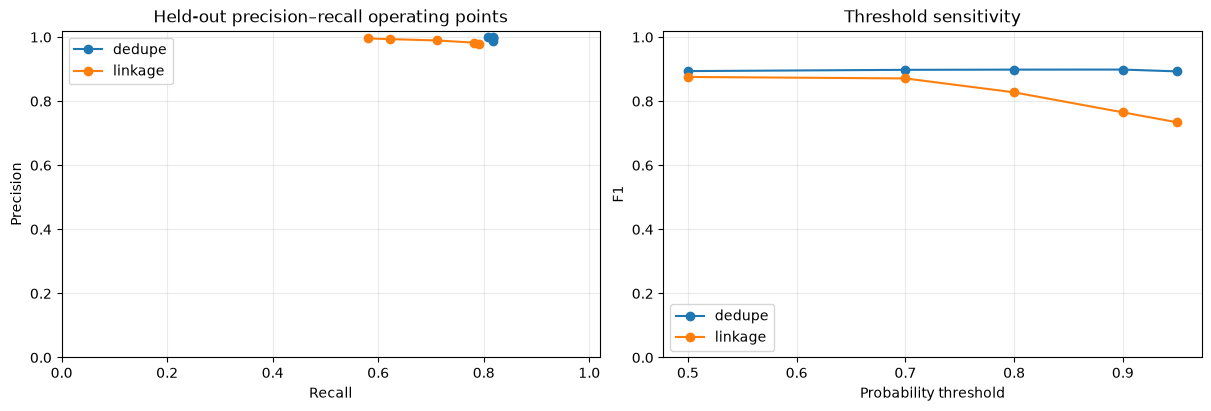

,strategy,candidates,possible_pairs,reduction_ratio,blocking_recall,count_seconds,experiment
0,strict,1094,526712196,0.999998,0.339900,0.077462,dedupe
1,original broad,5221749,526712196,0.990086,0.664441,10.771952,dedupe
2,targeted,39580,526712196,0.999925,0.876795,12.076523,dedupe
3,strict,97,868009444,1.000000,0.000000,0.041228,linkage
4,original broad,8616522,868009444,0.990073,0.253785,4.282655,linkage
5,targeted,91051,868009444,0.999895,0.966397,10.549888,linkage


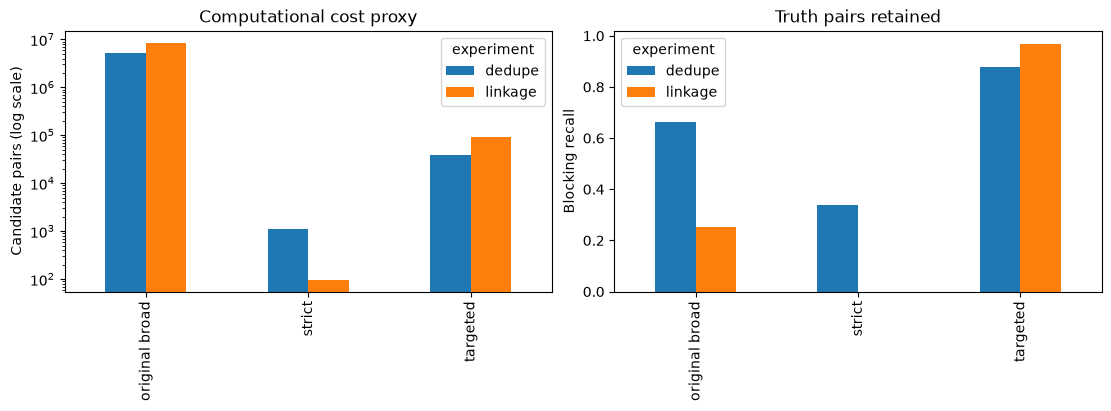

,seconds
dedupe prediction seconds,0.347278
linkage prediction seconds,0.564656


In [11]:
comparison = pd.concat([dedupe_metrics.assign(experiment='dedupe'),
                        linkage_metrics.assign(experiment='linkage')], ignore_index=True)
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, group in comparison.groupby('experiment'):
    axes[0].plot(group.recall, group.precision, 'o-', label=name)
    axes[1].plot(group.threshold, group.F1, 'o-', label=name)
axes[0].set(xlabel='Recall', ylabel='Precision', title='Held-out precision–recall operating points',
            xlim=(0,1.02), ylim=(0,1.02))
axes[1].set(xlabel='Probability threshold', ylabel='F1', title='Threshold sensitivity', ylim=(0,1.02))
for ax in axes:
    ax.grid(alpha=.25); ax.legend()
plt.show()
blocking_comparison = pd.concat([dedupe_blocking.assign(experiment='dedupe'),
                                linkage_blocking.assign(experiment='linkage')])
display(blocking_comparison)
fig, axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
blocking_comparison.pivot(index='strategy',columns='experiment',values='candidates').plot.bar(ax=axes[0],logy=True)
blocking_comparison.pivot(index='strategy',columns='experiment',values='blocking_recall').plot.bar(ax=axes[1])
axes[0].set(ylabel='Candidate pairs (log scale)',title='Computational cost proxy',xlabel='')
axes[1].set(ylabel='Blocking recall',ylim=(0,1.02),title='Truth pairs retained',xlabel='')
plt.show()
display(pd.Series({'dedupe prediction seconds':dedupe_predict_seconds,
                   'linkage prediction seconds':linkage_predict_seconds}).to_frame('seconds'))

## 10. Discussion and Conclusion
**Development evaluation:** this revision was iterated after inspecting the original
two-session model's held-out results. Consequently this split is a development holdout,
not an untouched final test set. A publication claiming generalisation needs a new,
independent dataset/time period with these choices frozen. No best test threshold is selected.

The generated summary below anchors the discussion to this run. High probabilities are
model outputs, not proof of identity. Review false positives for legitimate transactions
with repeated features and false negatives for blocking exclusions versus scoring failures.
The stricter and broader blocking counts isolate the recall/cost trade-off without
confounding it with retrained models. Only the preselected targeted strategy is scored.

Limitations: synthetic perturbations cover a narrow error family; labels are assumed
authoritative and complete in these sample datasets; training-only labels calibrate the
prior; EM estimates may be biased by blocking; rare u levels remain sampling-sensitive;
no probability calibration study or uncertainty intervals are included. An entity split
does not guarantee merchant-level or temporal independence. A production study should
validate on a separate source/time period, stress-test error mechanisms and missingness,
increase the u sampling budget, and set operating thresholds on a validation partition.
Training on 35% of entities intentionally makes the evaluated dataset smaller than the
full source. Neither experiment performs financial reconciliation or multi-payment assignment.

Every injected copy has a description edit. This deliberately leaves almost no true exact-memo matches in the dedupe training population, so its estimated exact-memo weight can be strongly negative. Do not reuse this fitted model for a population containing many unchanged imports without representative training data. The parameter tables make this benchmark-specific behaviour visible.

Some EM sessions use the full default 25-iteration budget. Splink may print a convergence message at that limit; this does not establish that the final parameter change is below tolerance. Inspect the iteration logs and perform a budget/initialisation sensitivity study before drawing stronger conclusions.

In [12]:
for name, metrics in [('Duplicate detection', dedupe_metrics), ('Record linkage', linkage_metrics)]:
    row = metrics.set_index('threshold').loc[REPORT_THRESHOLD]
    display(Markdown(f'**{name}, held-out threshold {REPORT_THRESHOLD}:** '
        f'TP={int(row.TP):,}, FP={int(row.FP):,}, FN={int(row.FN):,}; '
        f'precision={row.precision:.3f}, recall={row.recall:.3f}, F1={row.F1:.3f}; '
        f'blocking recall={row.blocking_recall:.3f}.'))
pd.testing.assert_frame_equal(df_origin, origin_snapshot)
pd.testing.assert_frame_equal(df_destination, destination_snapshot)
print('Original source data remained unchanged. All notebook assertions passed.')

**Duplicate detection, held-out threshold 0.8:** TP=2,446, FP=4, FN=549; precision=0.998, recall=0.817, F1=0.898; blocking recall=0.877.

**Record linkage, held-out threshold 0.8:** TP=20,952, FP=224, FN=8,510; precision=0.989, recall=0.711, F1=0.828; blocking recall=0.966.

Original source data remained unchanged. All notebook assertions passed.


### Sources and revision notes
API behaviour was checked against the installed **Splink 5.0.0** package and its signatures.
See the [Splink 5 release notes](https://moj-analytical-services.github.io/splink/blog/2026/09/28/splink-500-released.html)
and [versioned training implementation](https://github.com/moj-analytical-services/splink/blob/v5.0.0/splink/internals/linker_components/training.py).
The original 23 cells and all saved outputs were reviewed. Its two EM sessions jointly
estimated all comparisons; the first session's missing-amount warning was temporary.
The previous near-perfect synthetic results (4,533 TP, 3 FP, 0 FN at 0.7) described a
much easier benchmark where date and amount were unchanged. Those stale outputs were
removed, along with duplicated imports, unused scikit-learn metrics and the contradictory
claim that no exact duplicates were found. The original table-registration API was retained.